# 03 — Analyses de révision (R1) sur les données corrigées

Lit `outputs/dffinal_clean.xlsx` produit par `01_Data_Cleaning_Preparation_R1.ipynb` (créatinine de base, fenêtre de séjour et dates de premier épisode corrigées). Produit les analyses complémentaires demandées par les reviewers : risques compétitifs, landmark, ajustement étendu, score de propension, TBSA continu, Cox pour l'AKI, et les figures R1–R3.

**Dépendances** : pandas, numpy, matplotlib, statsmodels, lifelines.

In [1]:
import pandas as pd, numpy as np, json, os, warnings
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
import statsmodels.api as sm
from lifelines import CoxTimeVaryingFitter, CoxPHFitter
warnings.filterwarnings('ignore')

DATA_FOLDER = "outputs/"
OUT = "figures/"; RES = "outputs/results/"; os.makedirs(OUT, exist_ok=True); os.makedirs(RES, exist_ok=True)

df = pd.read_excel(DATA_FOLDER + "dffinal_clean.xlsx")
for c in ['D.burn','D.entry','D.discharge','D.death','D.RRT','AKI_date','first_natremia_below_135_date','first_natremia_above_145_date']:
    df[c] = pd.to_datetime(df[c], errors='coerce')
df['MAKE']  = df['MAKE90'].astype(int)                       # = MAKE_at_discharge du notebook 02
df['hypo']  = (df['min_natremia_value'] < 135).astype(int)
df['hyper'] = (df['max_natremia_value'] > 145).astype(int)
print(len(df), 'patients | hypo', df.hypo.sum(), '| hyper', df.hyper.sum(), '| both', (df.hypo & df.hyper).sum(), '| MAKE', df.MAKE.sum(), '| deaths', df.death.sum())

1758 patients | hypo 888 | hyper 418 | both 316 | MAKE 207 | deaths 163


## 1. Cox temps-dépendant pour MAKE — modèle principal et analyses de sensibilité (R1.8, R1.9, R1.11, R2.3)
Entrée retardée à l'admission, ajustement étendu, composantes datées (décès / EER), strates de TBSA, interaction, TBSA en classes, E-values.

In [2]:
R = {}
df['TBSA10']=df.TBSA/10; df['Age10']=df.Age/10
for c in ['IGSII','mechanical_ventilation_D1','DelaiPEC','creat_baseline']: df[c]=df[c].fillna(df[c].median())
df['lcreat']=np.log(df.creat_baseline)
ENR=['inhalation','IGSII','Charlson','mechanical_ventilation_D1','TBSAfull','lcreat','Sex']

def build(origin='D.burn',make='MAKE90',make28='MAKE28',covs=('Age','TBSA'),delayed=False,outcome='make',sub=None):
    rows=[]
    d=df if sub is None else df[sub]
    for i,r in d.iterrows():
        o=r[origin]
        if pd.isnull(o): o=r['D.entry']
        cand=[]
        if pd.notnull(r['D.death']):
            x=(r['D.death']-o).days
            if x>0: cand.append(x)
        if outcome in('make','hard') and pd.notnull(r['D.RRT']):
            x=(r['D.RRT']-o).days
            if x>0: cand.append(x)
        if outcome=='make':
            if r[make28]==1: cand.append(28)
            if r[make]==1: cand.append(90)
        cand=[c for c in cand if c<=90]
        t,e=(min(cand),1) if cand else (90,0)
        def tt(c):
            if pd.isnull(r[c]): return np.inf
            x=(r[c]-o).days
            return np.inf if x<0 else x
        h,H2=tt('first_natremia_below_135_date'),tt('first_natremia_above_145_date')
        s0=0
        if delayed:
            s0=max(0,(r['D.entry']-o).days)
            if s0>=t: continue
        cuts=sorted(set([s0]+[c for c in (h,H2) if s0<c<t]+[t]))
        for a,b in zip(cuts[:-1],cuts[1:]):
            row={'id':i,'start':a,'stop':b,'event':int(e if b==t else 0),'hyponatremia':int(a>=h),'hypernatremia':int(a>=H2)}
            for c in covs: row[c]=r[c]
            rows.append(row)
    return pd.DataFrame(rows)
def fit(name,pen=0.0,**k):
    L=build(**k); m=CoxTimeVaryingFitter(penalizer=pen); m.fit(L,id_col='id',start_col='start',stop_col='stop',event_col='event')
    s=m.summary; out={'n':int(L.id.nunique()),'events':int(L.event.sum())}
    for v in s.index: out[v]=[round(float(np.exp(s.loc[v,'coef'])),2),round(float(np.exp(s.loc[v,'coef lower 95%'])),2),round(float(np.exp(s.loc[v,'coef upper 95%'])),2),float(s.loc[v,'p'])]
    R[name]=out; print(name,{k:v for k,v in out.items() if k in('n','events','hyponatremia','hypernatremia')}); return m
fit('origin_burn')
fit('delayed_entry',delayed=True)
fit('enriched',covs=tuple(['Age','TBSA']+ENR),delayed=True)
fit('death_only',outcome='death',delayed=True)
fit('death_or_KRT',outcome='hard',delayed=True)
fit('death_only_enriched',outcome='death',delayed=True,covs=tuple(['Age','TBSA']+ENR))
for lab,msk in [('TBSA<20',df.TBSA<20),('TBSA20-39',(df.TBSA>=20)&(df.TBSA<40)),('TBSA>=40',df.TBSA>=40)]:
    print(lab,int(msk.sum()),'MAKE',int(df.MAKE[msk].sum())); fit('strat_'+lab,pen=0.01,sub=msk,delayed=True)
# interaction
L=build(delayed=True); L['hypoxTBSA10']=L.hyponatremia*L.TBSA/10; L['hyperxTBSA10']=L.hypernatremia*L.TBSA/10
m=CoxTimeVaryingFitter().fit(L,id_col='id',start_col='start',stop_col='stop',event_col='event'); s=m.summary
R['interaction']={v:[round(float(np.exp(s.loc[v,'coef'])),3),float(s.loc[v,'p'])] for v in s.index}; print(R['interaction'])
# TBSA categories instead of continuous
L=build(delayed=True); L['TBSA_20_39']=((L.TBSA>=20)&(L.TBSA<40)).astype(int); L['TBSA_ge40']=(L.TBSA>=40).astype(int); L=L.drop(columns='TBSA')
m=CoxTimeVaryingFitter().fit(L,id_col='id',start_col='start',stop_col='stop',event_col='event'); s_=m.summary
R['tbsa_categories']={v:[round(float(np.exp(s_.loc[v,'coef'])),2),round(float(np.exp(s_.loc[v,'coef lower 95%'])),2),round(float(np.exp(s_.loc[v,'coef upper 95%'])),2),float(s_.loc[v,'p'])] for v in s_.index}; print(R['tbsa_categories'])
# E-values
def ev(hr,lo):
    f=lambda x: x+np.sqrt(x*(x-1))
    return round(f(hr),2), round(f(lo),2) if lo>1 else 1.0
for k in ['delayed_entry','enriched']:
    for v in ['hyponatremia','hypernatremia']:
        R[k+'_Evalue_'+v]=ev(R[k][v][0],R[k][v][1]); print(k,v,'E-value',R[k+'_Evalue_'+v])
Rc = R
json.dump(Rc, open(RES+'R_cox.json','w'), indent=1, default=float)

origin_burn {'n': 1758, 'events': 222, 'hyponatremia': [1.15, 0.85, 1.55, 0.37683213097537005], 'hypernatremia': [4.03, 2.92, 5.56, 2.2969649647354738e-17]}


delayed_entry {'n': 1745, 'events': 212, 'hyponatremia': [1.09, 0.81, 1.47, 0.5786698847063642], 'hypernatremia': [3.98, 2.9, 5.44, 7.469434714647002e-18]}


enriched {'n': 1745, 'events': 212, 'hyponatremia': [1.23, 0.9, 1.68, 0.1956797823208668], 'hypernatremia': [2.34, 1.65, 3.31, 2.0761072256131093e-06]}


death_only {'n': 1753, 'events': 138, 'hyponatremia': [1.17, 0.8, 1.71, 0.41870142385902187], 'hypernatremia': [5.2, 3.5, 7.73, 3.7303437772111635e-16]}


death_or_KRT {'n': 1746, 'events': 160, 'hyponatremia': [1.43, 1.0, 2.04, 0.048928614074238624], 'hypernatremia': [5.47, 3.8, 7.86, 4.408162468185188e-20]}


death_only_enriched {'n': 1753, 'events': 138, 'hyponatremia': [1.39, 0.94, 2.07, 0.10109181200989815], 'hypernatremia': [3.15, 2.02, 4.91, 3.934294238339739e-07]}
TBSA<20 1241 MAKE 62


strat_TBSA<20 {'n': 1237, 'events': 62, 'hyponatremia': [1.15, 0.72, 1.84, 0.5487009621398861], 'hypernatremia': [7.36, 4.48, 12.08, 2.903096850583831e-15]}
TBSA20-39 302 MAKE 55
strat_TBSA20-39 {'n': 297, 'events': 57, 'hyponatremia': [1.07, 0.61, 1.89, 0.8057285561281965], 'hypernatremia': [3.36, 1.88, 6.0, 4.1952968915279566e-05]}
TBSA>=40 215 MAKE 90
strat_TBSA>=40 {'n': 211, 'events': 93, 'hyponatremia': [0.72, 0.44, 1.18, 0.1862575371020923], 'hypernatremia': [1.41, 0.84, 2.34, 0.1923431974412268]}


{'hyponatremia': [1.29, 0.30769389038586503], 'hypernatremia': [8.935, 1.6094038953162414e-19], 'Age': [1.042, 3.766859014840859e-25], 'TBSA': [1.044, 2.0868031318133246e-33], 'hypoxTBSA10': [0.944, 0.28964162592326104], 'hyperxTBSA10': [0.806, 1.8940181755387533e-05]}


{'hyponatremia': [0.96, 0.71, 1.3, 0.7906446809899175], 'hypernatremia': [3.68, 2.64, 5.14, 1.8081252908714002e-14], 'Age': [1.05, 1.04, 1.06, 5.15717288793986e-32], 'TBSA_20_39': [2.62, 1.79, 3.84, 7.883525388997485e-07], 'TBSA_ge40': [5.87, 4.02, 8.56, 4.1981286192611703e-20]}
delayed_entry hyponatremia E-value (np.float64(1.4), 1.0)
delayed_entry hypernatremia E-value (np.float64(7.42), np.float64(5.25))
enriched hyponatremia E-value (np.float64(1.76), 1.0)
enriched hypernatremia E-value (np.float64(4.11), np.float64(2.69))


## 2. Temps depuis l'admission en réanimation (premier épisode d'hypo/hypernatrémie, AKI) et décès en réanimation
Préparation des variables de temps utilisées par les sections 3 à 8.

Pour l'incidence cumulée (Supp Fig 9), l'origine est la **date de brûlure** (R1-FIX 12), comme dans le reste du papier.


In [3]:
R = {}
E_=df['D.entry']
def day(c):
    x=(df[c].dt.normalize()-E_).dt.days
    return x.clip(lower=0)
df['t_hypo']=day('first_natremia_below_135_date'); df['t_hyper']=day('first_natremia_above_145_date'); df['t_aki']=day('AKI_date')
df['stay']=df['T.stay'].astype(float)
df['died_icu']=((df.death==1)&(df['D.death']<=df['D.discharge'])).astype(int)
for c in ['t_hypo','t_hyper','t_aki']: df.loc[df[c]>df.stay,c]=np.nan   # outside ICU stay
print('in-stay first events: hypo',df.t_hypo.notna().sum(),'hyper',df.t_hyper.notna().sum(),'aki',df.t_aki.notna().sum(),'died in ICU',df.died_icu.sum())
# R1-FIX 12 : pour l'incidence cumulee (Supp Fig 9 / Fig R1), origine = date de brulure (comme le Cox principal
# et les autres analyses de delai du papier) ; les autres analyses de cette section restent depuis l'admission.
B_=df['D.burn'].fillna(df['D.entry'])
def day_b(c):
    return (df[c].dt.normalize()-B_.dt.normalize()).dt.days.clip(lower=0)
df['t_hypo_b']=day_b('first_natremia_below_135_date'); df['t_hyper_b']=day_b('first_natremia_above_145_date'); df['t_aki_b']=day_b('AKI_date')
df['stay_b']=(df['D.discharge'].dt.normalize()-B_.dt.normalize()).dt.days.astype(float)
for c in ['t_hypo_b','t_hyper_b','t_aki_b']: df.loc[df[c]>df.stay_b,c]=np.nan
print('from burn: first events in stay: hypo',df.t_hypo_b.notna().sum(),'hyper',df.t_hyper_b.notna().sum(),'aki',df.t_aki_b.notna().sum())


in-stay first events: hypo 888 hyper 418 aki 404 died in ICU 155
from burn: first events in stay: hypo 888 hyper 418 aki 404


## 3. Incidence cumulée avec risques compétitifs (R1.8, R2.2)
Tous les patients sont suivis jusqu'au décès ou à la sortie : pas de censure, l'estimateur d'Aalen-Johansen est donc la proportion empirique.

In [4]:
# ---- CIF (no censoring: every patient followed to death/discharge) -> empirical AJ ; origine = brulure (R1-FIX 12)
N=len(df); grid=[3,7,14,30,60]
cif={}
for ev in ['hypo','hyper','aki']:
    t=df['t_'+ev+'_b']; has=t.notna()
    comp_d=(~has)&(df.died_icu==1); comp_a=(~has)&(df.died_icu==0)
    cif[ev]={'event':{g:round(100*((t<=g)&has).sum()/N,1) for g in grid},
             'death_without':{g:round(100*(comp_d&(df.stay_b<=g)).sum()/N,1) for g in grid},
             'discharge_without':{g:round(100*(comp_a&(df.stay_b<=g)).sum()/N,1) for g in grid},
             'n_event':int(has.sum()),'n_death_without':int(comp_d.sum()),'n_disch_without':int(comp_a.sum()),
             'median_day':[float(t[has].median()),float(t[has].quantile(.25)),float(t[has].quantile(.75))]}
    print(ev,cif[ev])
R['cif']=cif
# early deaths: opportunity to develop dysnatremia
for g in [2,3,7]:
    m=(df.died_icu==1)&(df.stay<=g); print('died within',g,'d:',m.sum(),'with hyper',df.loc[m,'hyper'].sum(),'hypo',df.loc[m,'hypo'].sum())
R['early_death']={g:[int(((df.died_icu==1)&(df.stay<=g)).sum()),int(df.loc[(df.died_icu==1)&(df.stay<=g),'hyper'].sum()),int(df.loc[(df.died_icu==1)&(df.stay<=g),'hypo'].sum())] for g in [2,3,7]}

hypo {'event': {3: np.float64(24.2), 7: np.float64(30.4), 14: np.float64(38.5), 30: np.float64(47.0), 60: np.float64(49.9)}, 'death_without': {3: np.float64(1.9), 7: np.float64(2.5), 14: np.float64(3.2), 30: np.float64(3.8), 60: np.float64(4.5)}, 'discharge_without': {3: np.float64(7.4), 7: np.float64(12.5), 14: np.float64(22.5), 30: np.float64(37.9), 60: np.float64(43.7)}, 'n_event': 888, 'n_death_without': 82, 'n_disch_without': 788, 'median_day': [4.0, 2.0, 14.0]}
hyper {'event': {3: np.float64(8.2), 7: np.float64(16.6), 14: np.float64(20.5), 30: np.float64(23.0), 60: np.float64(23.5)}, 'death_without': {3: np.float64(1.5), 7: np.float64(2.1), 14: np.float64(2.3), 30: np.float64(2.4), 60: np.float64(2.7)}, 'discharge_without': {3: np.float64(7.7), 7: np.float64(13.6), 14: np.float64(27.9), 30: np.float64(58.4), 60: np.float64(71.0)}, 'n_event': 418, 'n_death_without': 50, 'n_disch_without': 1290, 'median_day': [5.0, 2.0, 9.0]}
aki {'event': {3: np.float64(11.3), 7: np.float64(14.2),

## 4. Facteurs associés : modèles cause-spécifiques et de Fine-Gray (R1.8)
Sans censure, le modèle de Fine-Gray s'obtient en maintenant dans l'ensemble à risque les patients ayant eu l'événement compétitif.

In [5]:
# ---- cause-specific & Fine-Gray (exact without censoring) for first hypo / hyper
covs=['Age10','TBSA10','Sex','inhalation','Charlson','diabete','OH','renal.disease','congestive.heart.failure','mechanical_ventilation_D1']
HOR=90
for ev in ['hypo','hyper']:
    t=df['t_'+ev]; has=t.notna()
    d=df[covs].copy().astype(float)
    d['T']=np.where(has,t,df.stay).astype(float)+0.5; d['E']=has.astype(int)
    cs=CoxPHFitter().fit(d,'T','E')
    d2=d.copy(); d2.loc[~has,'T']=1000.0   # competing events stay in risk set (subdistribution hazard, no censoring)
    fg=CoxPHFitter().fit(d2,'T','E')
    out={}
    for v in covs:
        out[v]={'csHR':[round(float(np.exp(cs.params_[v])),2)]+[round(float(x),2) for x in np.exp(cs.confidence_intervals_.loc[v])]+[float(cs.summary.loc[v,'p'])],
                'sHR':[round(float(np.exp(fg.params_[v])),2)]+[round(float(x),2) for x in np.exp(fg.confidence_intervals_.loc[v])]+[float(fg.summary.loc[v,'p'])]}
    R['factors_'+ev]=out; print(ev); [print('  ',k,v['csHR'][:3],v['sHR'][:3]) for k,v in out.items()]

hypo
   Age10 [1.02, 0.97, 1.07] [1.03, 0.98, 1.09]
   TBSA10 [1.09, 1.05, 1.14] [1.12, 1.08, 1.17]
   Sex [1.06, 0.93, 1.22] [1.02, 0.89, 1.17]
   inhalation [0.7, 0.57, 0.87] [0.69, 0.56, 0.85]
   Charlson [1.01, 0.96, 1.06] [1.0, 0.96, 1.05]
   diabete [1.1, 0.89, 1.38] [1.18, 0.95, 1.47]
   OH [1.27, 1.07, 1.5] [1.41, 1.19, 1.67]
   renal.disease [1.2, 0.81, 1.77] [1.2, 0.81, 1.79]
   congestive.heart.failure [0.89, 0.62, 1.3] [1.0, 0.69, 1.44]
   mechanical_ventilation_D1 [1.0, 0.82, 1.22] [1.29, 1.05, 1.57]
hyper
   Age10 [1.18, 1.09, 1.28] [1.14, 1.06, 1.24]
   TBSA10 [1.27, 1.21, 1.33] [1.16, 1.11, 1.21]
   Sex [1.21, 0.99, 1.49] [1.12, 0.91, 1.38]
   inhalation [1.51, 1.2, 1.89] [1.32, 1.05, 1.65]
   Charlson [0.98, 0.91, 1.06] [0.94, 0.88, 1.01]
   diabete [0.61, 0.42, 0.87] [0.72, 0.51, 1.03]
   OH [1.3, 1.03, 1.64] [1.4, 1.11, 1.77]
   renal.disease [1.05, 0.62, 1.8] [1.36, 0.8, 2.31]
   congestive.heart.failure [2.56, 1.67, 3.93] [2.44, 1.59, 3.73]
   mechanical_ventilatio

## 5. Analyses landmark J3 / J7 / J14 — régression logistique (R1.8, R1.11)

In [6]:
# ---- landmark logistic
ENR=['inhalation','IGSII','Charlson','mechanical_ventilation_D1','TBSAfull','lcreat','Sex']
dd=(df['D.death']-E_).dt.days; dr=(df['D.RRT']-E_).dt.days
def lm(L,outcome='MAKE',covs=('Age10','TBSA10')):
    s=(df.stay>L)&~(dd<=L)&~(dr<=L)
    d=df[s].copy(); d['hypoL']=(d.t_hypo<=L).astype(int); d['hyperL']=(d.t_hyper<=L).astype(int)
    X=sm.add_constant(d[['hypoL','hyperL']+list(covs)].astype(float)); m=sm.Logit(d[outcome].astype(float),X).fit(disp=0)
    ci=np.exp(m.conf_int()); o={'n':int(len(d)),'events':int(d[outcome].sum()),'n_hypo':int(d.hypoL.sum()),'n_hyper':int(d.hyperL.sum()),
       'make_hypo':f"{int(d.loc[d.hypoL==1,outcome].sum())}/{int(d.hypoL.sum())}",'make_hyper':f"{int(d.loc[d.hyperL==1,outcome].sum())}/{int(d.hyperL.sum())}",
       'make_neither':f"{int(d.loc[(d.hypoL==0)&(d.hyperL==0),outcome].sum())}/{int(((d.hypoL==0)&(d.hyperL==0)).sum())}"}
    for v in ['hypoL','hyperL']: o[v]=[round(float(np.exp(m.params[v])),2),round(float(ci.loc[v,0]),2),round(float(ci.loc[v,1]),2),float(m.pvalues[v])]
    return o,d
for L in [3,7,14]:
    for nm,cv in [('main',('Age10','TBSA10')),('enriched',tuple(['Age10','TBSA10']+ENR))]:
        o,_=lm(L,covs=cv); R[f'landmark{L}_{nm}']=o; print('LM',L,nm,o)
o,_=lm(7,outcome='death'); R['landmark7_death']=o; print('LM7 death',o)

LM 3 main {'n': 1466, 'events': 125, 'n_hypo': 557, 'n_hyper': 152, 'make_hypo': '45/557', 'make_hyper': '40/152', 'make_neither': '48/786', 'hypoL': [1.21, 0.78, 1.88, 0.3989069500159593], 'hyperL': [2.0, 1.14, 3.52, 0.016225772387353652]}
LM 3 enriched {'n': 1466, 'events': 125, 'n_hypo': 557, 'n_hyper': 152, 'make_hypo': '45/557', 'make_hyper': '40/152', 'make_neither': '48/786', 'hypoL': [1.34, 0.84, 2.13, 0.2239442789765831], 'hyperL': [1.65, 0.92, 2.96, 0.08999788111315343]}
LM 7 main {'n': 1213, 'events': 97, 'n_hypo': 608, 'n_hyper': 270, 'make_hypo': '45/608', 'make_hyper': '58/270', 'make_neither': '12/429', 'hypoL': [1.45, 0.88, 2.37, 0.1437349347529868], 'hyperL': [3.16, 1.76, 5.67, 0.00011384815719968114]}
LM 7 enriched {'n': 1213, 'events': 97, 'n_hypo': 608, 'n_hyper': 270, 'make_hypo': '45/608', 'make_hyper': '58/270', 'make_neither': '12/429', 'hypoL': [1.5, 0.9, 2.51, 0.11965627276222367], 'hyperL': [2.21, 1.15, 4.27, 0.01764089423074922]}
LM 14 main {'n': 804, 'event

## 6. Score de propension — overlap weighting, hypernatrémie avant J7 (R1.9)

In [7]:
# ---- overlap weighting PS, hyper by day 7
_,d=lm(7); pc=['Age10','TBSA10']+ENR+['diabete','renal.disease','congestive.heart.failure','DelaiPEC']
Xp=sm.add_constant(d[pc].astype(float)); ps=sm.Logit(d.hyperL.astype(float),Xp).fit(disp=0).predict(Xp)
w=np.where(d.hyperL==1,1-ps,ps)
def smd(v,w=None):
    a,b=d.loc[d.hyperL==1,v].astype(float),d.loc[d.hyperL==0,v].astype(float)
    if w is None: ma,mb,va,vb=a.mean(),b.mean(),a.var(),b.var()
    else:
        wa,wb=w[d.hyperL==1],w[d.hyperL==0]; ma,mb=np.average(a,weights=wa),np.average(b,weights=wb); va,vb=a.var(),b.var()
    return abs(ma-mb)/np.sqrt((va+vb)/2)
R['ow_smd']={v:[round(smd(v),2),round(smd(v,w),3)] for v in pc}; print('SMD before/after',R['ow_smd'])
Xo=sm.add_constant(d[['hyperL','hypoL']].astype(float)); g=sm.GLM(d.MAKE.astype(float),Xo,family=sm.families.Binomial(),freq_weights=None,var_weights=w).fit(cov_type='HC1')
ci=np.exp(g.conf_int()); R['ow_hyper7']=[round(float(np.exp(g.params['hyperL'])),2),round(float(ci.loc['hyperL',0]),2),round(float(ci.loc['hyperL',1]),2),float(g.pvalues['hyperL'])]; print('OW OR hyper7',R['ow_hyper7'],'c-stat PS n',len(d))

SMD before/after {'Age10': [np.float64(0.08), np.float64(0.0)], 'TBSA10': [np.float64(1.3), np.float64(0.0)], 'inhalation': [np.float64(0.77), np.float64(0.0)], 'IGSII': [np.float64(0.94), np.float64(0.0)], 'Charlson': [np.float64(0.03), np.float64(0.0)], 'mechanical_ventilation_D1': [np.float64(1.66), np.float64(0.0)], 'TBSAfull': [np.float64(1.06), np.float64(0.0)], 'lcreat': [np.float64(0.23), np.float64(0.0)], 'Sex': [np.float64(0.21), np.float64(0.0)], 'diabete': [np.float64(0.21), np.float64(0.0)], 'renal.disease': [np.float64(0.13), np.float64(0.0)], 'congestive.heart.failure': [np.float64(0.28), np.float64(0.0)], 'DelaiPEC': [np.float64(0.4), np.float64(0.0)]}
OW OR hyper7 [1.7, 0.91, 3.18, 0.09641736015589666] c-stat PS n 1213


## 7. Dysnatrémie à l'admission : TBSA continu et en classes (R2.3)

In [8]:
# ---- admission dysnatremia: TBSA continuous
df['hypo_adm']=(df.first_natremia_value<135).astype(int); df['hyper_adm']=(df.first_natremia_value>145).astype(int)
cat=['Sex','smoke','OH','AVC','hypertension','ischemic.cardiac_disease','congestive.heart.failure','peripheral.vasc.disease','renal.disease','cancer','diabete','electric.burn','chemical.burn','inhalation','hydrocobalamine','pulmonary.disease']
for oc in ['hypo_adm','hyper_adm']:
    for nm,extra in [('cont',['TBSA10']),('cat',['TBSA_20_39','TBSA_ge40'])]:
        d=df.copy(); d['TBSA_20_39']=((d.TBSA>=20)&(d.TBSA<40)).astype(int); d['TBSA_ge40']=(d.TBSA>=40).astype(int)
        d=d[cat+['Age10','Charlson','IMC',oc]+extra].dropna().astype(float)
        m=sm.Logit(d[oc],sm.add_constant(d.drop(columns=oc))).fit(disp=0,method='lbfgs',maxiter=20000,pgtol=1e-10,factr=10); ci=np.exp(m.conf_int())
        o={v:[round(float(np.exp(m.params[v])),2),round(float(ci.loc[v,0]),2),round(float(ci.loc[v,1]),2),round(float(m.pvalues[v]),4)] for v in m.params.index if v!='const'}
        o['_n']=[int(len(d)),int(d[oc].sum())]; R[f'adm_{oc}_{nm}']=o
        print(oc,nm,o['_n'],{k:v for k,v in o.items() if k!='_n' and (v[3]<0.05 or k in extra)})

hypo_adm cont [1698, 237] {'OH': [1.46, 1.0, 2.13, 0.0479], 'diabete': [2.0, 1.25, 3.18, 0.0035], 'electric.burn': [0.33, 0.12, 0.93, 0.0367], 'hydrocobalamine': [0.26, 0.09, 0.77, 0.0152], 'TBSA10': [1.07, 0.99, 1.16, 0.102]}


hypo_adm cat [1698, 237] {'diabete': [2.02, 1.27, 3.23, 0.0032], 'electric.burn': [0.35, 0.13, 0.99, 0.0477], 'hydrocobalamine': [0.25, 0.09, 0.76, 0.0137], 'IMC': [0.97, 0.94, 1.0, 0.0437], 'TBSA_20_39': [1.74, 1.23, 2.46, 0.0016], 'TBSA_ge40': [1.06, 0.63, 1.78, 0.8264]}


hyper_adm cont [1698, 61] {'OH': [2.11, 1.08, 4.1, 0.0283], 'inhalation': [2.3, 1.15, 4.62, 0.0189], 'TBSA10': [1.27, 1.14, 1.42, 0.0]}


hyper_adm cat [1698, 61] {'OH': [2.05, 1.06, 3.99, 0.0333], 'inhalation': [2.46, 1.24, 4.88, 0.0102], 'TBSA_20_39': [2.29, 1.14, 4.59, 0.0204], 'TBSA_ge40': [4.05, 2.03, 8.08, 0.0001]}


## 8. Cox temps-dépendant pour l'AKI — exposition précédant l'AKI (R2.2)

In [9]:
# ---- AKI time-varying Cox from admission (exposure must precede AKI)
rows=[]
for i,r in df.iterrows():
    t=r.t_aki if pd.notnull(r.t_aki) else r.stay; e=int(pd.notnull(r.t_aki)); t=float(t)+0.5
    h=r.t_hypo if pd.notnull(r.t_hypo) else np.inf; H2=r.t_hyper if pd.notnull(r.t_hyper) else np.inf
    h+=0.75; H2+=0.75   # exposure switched on the day AFTER first dysnatremia -> same-day events not attributed
    cuts=sorted(set([0]+[c for c in (h,H2) if 0<c<t]+[t]))
    for a,b in zip(cuts[:-1],cuts[1:]):
        rows.append({'id':i,'start':a,'stop':b,'event':int(e if b==t else 0),'hyponatremia':int(a>=h),'hypernatremia':int(a>=H2),'Age':r.Age,'TBSA':r.TBSA})
L=pd.DataFrame(rows); m=CoxTimeVaryingFitter().fit(L,id_col='id',start_col='start',stop_col='stop',event_col='event'); s=m.summary
R['aki_tv']={v:[round(float(np.exp(s.loc[v,'coef'])),2),round(float(np.exp(s.loc[v,'coef lower 95%'])),2),round(float(np.exp(s.loc[v,'coef upper 95%'])),2),float(s.loc[v,'p'])] for v in s.index}; R['aki_tv']['_events']=int(L.event.sum())
print('AKI TV',R['aki_tv'])
# AKI excluded if at day<=1
L2=L[~L.id.isin(df.index[df.t_aki<=1])]; m=CoxTimeVaryingFitter().fit(L2,id_col='id',start_col='start',stop_col='stop',event_col='event'); s=m.summary
R['aki_tv_excl_early']={v:[round(float(np.exp(s.loc[v,'coef'])),2),round(float(np.exp(s.loc[v,'coef lower 95%'])),2),round(float(np.exp(s.loc[v,'coef upper 95%'])),2),float(s.loc[v,'p'])] for v in s.index}; R['aki_tv_excl_early']['_events']=int(L2.event.sum()); print('AKI TV excl d0-1',R['aki_tv_excl_early'])

AKI TV {'hyponatremia': [1.01, 0.76, 1.32, 0.9693118580233392], 'hypernatremia': [2.55, 1.87, 3.48, 3.262066591005943e-09], 'Age': [1.04, 1.03, 1.04, 2.1473254080534228e-40], 'TBSA': [1.03, 1.02, 1.03, 8.21467233937686e-37], '_events': 404}
AKI TV excl d0-1 {'hyponatremia': [1.05, 0.77, 1.42, 0.766375684026803], 'hypernatremia': [3.14, 2.19, 4.51, 6.085729693296836e-10], 'Age': [1.04, 1.03, 1.04, 3.9989750984503413e-19], 'TBSA': [1.02, 1.01, 1.03, 2.6353232437247055e-08], '_events': 203}


## 9. Dénominateurs (R1.10) et volumes de remplissage (R1.5)
⚠️ Les volumes des 48 premières heures sont manifestement incomplets (médiane ≈ 1,3 mL/kg/%SCB/48 h chez les ≥ 20 %) : ne pas les citer.

In [10]:
# ---- descriptives
print('fluid 48h available',(df.first_intake_day.notna()).sum()); f=df[df.first_intake_day.notna()]
f=f.assign(mlkgtbsa=f.fluid_in_ml_first_48h/(f.weight*f.TBSA.replace(0,np.nan)))
for nm,mk in [('all',f.index==f.index),('hyper',f.hyper==1),('no hyper',f.hyper==0),('TBSA>=20',f.TBSA>=20)]:
    x=f.loc[mk,'fluid_in_ml_first_48h']; y=f.loc[mk&(f.TBSA>=20),'mlkgtbsa']
    print(nm,len(x),'mL48h',x.median().round(0),x.quantile([.25,.75]).round(0).tolist(),'| mL/kg/%TBSA/48h (TBSA>=20)',y.median().round(2),y.quantile([.25,.75]).round(2).tolist())
for g,lab in [('hyper','hyper'),('hypo','hypo')]:
    for v in [1,0]:
        m=df[g]==v; print(lab,v,'MAKE',int(df.MAKE[m].sum()),'/',int(m.sum()),'death',int(df.death[m].sum()),'/',int(m.sum()),'AKI',int(df.AKI_KDIGO[m].sum()))
m=(df.hypo==0)&(df.hyper==0); print('no dysnat MAKE',int(df.MAKE[m].sum()),'/',int(m.sum()))

fluid 48h available 858
all 858 mL48h 1115.0 [420.0, 2827.0] | mL/kg/%TBSA/48h (TBSA>=20) 1.28 [0.3, 3.54]
hyper 247 mL48h 2156.0 [846.0, 9167.0] | mL/kg/%TBSA/48h (TBSA>=20) 1.18 [0.28, 4.18]
no hyper 611 mL48h 896.0 [380.0, 1969.0] | mL/kg/%TBSA/48h (TBSA>=20) 1.34 [0.43, 2.95]
TBSA>=20 309 mL48h 2537.0 [853.0, 8947.0] | mL/kg/%TBSA/48h (TBSA>=20) 1.28 [0.3, 3.54]
hyper 1 MAKE 135 / 418 death 110 / 418 AKI 257
hyper 0 MAKE 72 / 1340 death 53 / 1340 AKI 147
hypo 1 MAKE 112 / 888 death 77 / 888 AKI 290
hypo 0 MAKE 95 / 870 death 86 / 870 AKI 114
no dysnat MAKE 44 / 768


In [11]:
Ra = json.loads(json.dumps(R, default=float))
json.dump(Ra, open(RES+'R_a3.json','w'), indent=1)

## 10. Figures de la réponse aux reviewers
Figure R1 (incidence cumulée, remplace la Supp Fig 9), Figure R2 (forest plot), Figure R3 (DAG).

In [12]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.spines.top':False,'axes.spines.right':False})
INK='#222222'; C_EV='#0072B2'; C_D='#D55E00'; C_A='#BBBBBB'

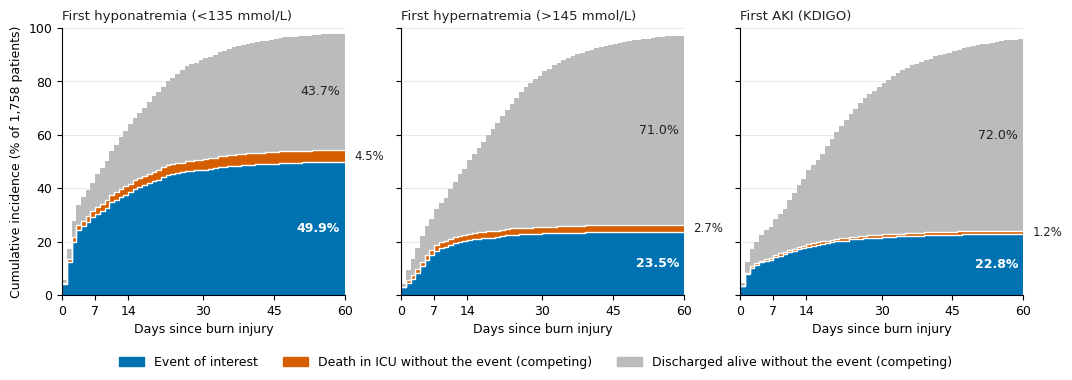

In [13]:
# ---------- Fig R1: stacked cumulative incidence with competing events (origine = brulure, R1-FIX 12)
N=len(df); g=np.arange(0,61)
fig,axs=plt.subplots(1,3,figsize=(11,3.8),sharey=True)
for ax,(ev,lab) in zip(axs,[('hypo','First hyponatremia (<135 mmol/L)'),('hyper','First hypernatremia (>145 mmol/L)'),('aki','First AKI (KDIGO)')]):
    t=df['t_'+ev+'_b']; has=t.notna(); cd=(~has)&(df.died_icu==1); ca=(~has)&(df.died_icu==0)
    e=np.array([((t<=x)&has).sum() for x in g])/N*100; d=np.array([(cd&(df.stay_b<=x)).sum() for x in g])/N*100; a=np.array([(ca&(df.stay_b<=x)).sum() for x in g])/N*100
    ax.fill_between(g,0,e,step='post',color=C_EV,lw=0); ax.fill_between(g,e,e+d,step='post',color=C_D,lw=0); ax.fill_between(g,e+d,e+d+a,step='post',color=C_A,lw=0)
    ax.step(g,e,where='post',color='white',lw=1); ax.step(g,e+d,where='post',color='white',lw=1)
    ax.set_title(lab,fontsize=9.5,color=INK,loc='left'); ax.set_xlabel('Days since burn injury'); ax.set_xlim(0,60); ax.set_ylim(0,100); ax.set_xticks([0,7,14,30,45,60])
    ax.grid(axis='y',color='#E6E6E6',lw=.6); ax.set_axisbelow(True)
    ax.text(59,e[-1]/2,f'{e[-1]:.1f}%',ha='right',va='center',color='white',fontweight='bold',fontsize=9)
    ax.text(59,e[-1]+d[-1]+a[-1]/2,f'{a[-1]:.1f}%',ha='right',va='center',color=INK,fontsize=9)
    ax.annotate(f'{d[-1]:.1f}%',xy=(60,e[-1]+d[-1]/2),xytext=(62,e[-1]+d[-1]/2),ha='left',va='center',fontsize=8.5,color=INK,annotation_clip=False)
axs[0].set_ylabel('Cumulative incidence (% of 1,758 patients)')
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=C_EV,label='Event of interest'),Patch(color=C_D,label='Death in ICU without the event (competing)'),Patch(color=C_A,label='Discharged alive without the event (competing)')],loc='lower center',ncol=3,frameon=False,fontsize=9)
fig.tight_layout(rect=(0,0.07,0.98,1)); fig.savefig(OUT+'FigR1_cumulative_incidence_competing_risks.png',dpi=300); plt.show()

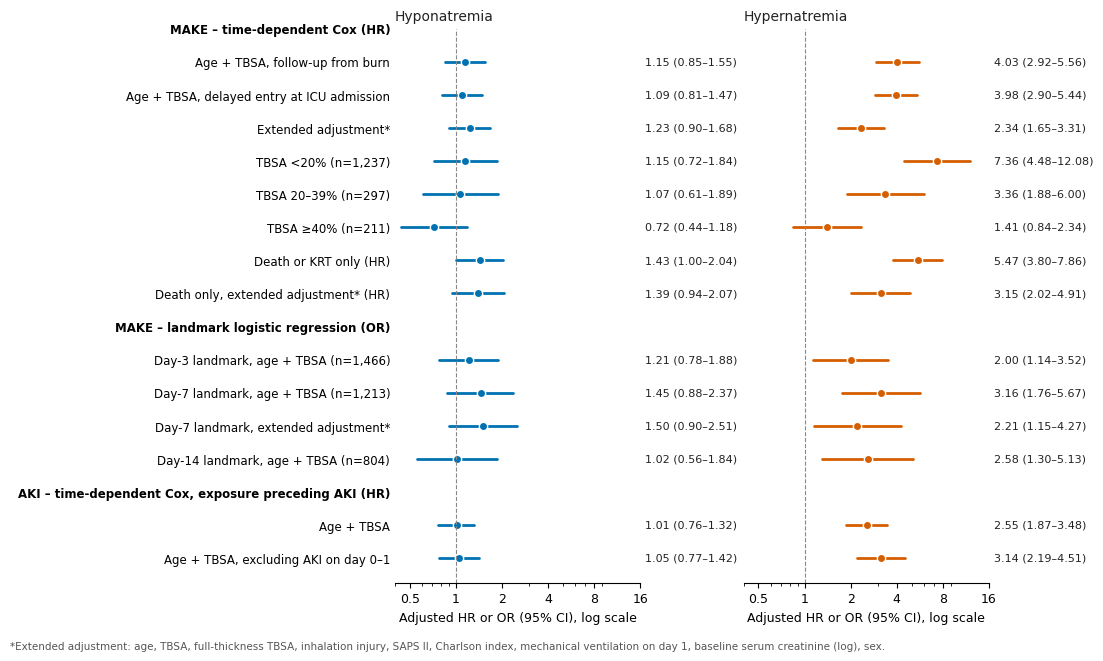

In [14]:
# ---------- Fig R2: forest plot
rows=[('MAKE – time-dependent Cox (HR)',None,None),
 ('Age + TBSA, follow-up from burn',Rc['origin_burn'],'c'),('Age + TBSA, delayed entry at ICU admission',Rc['delayed_entry'],'c'),
 ('Extended adjustment*',Rc['enriched'],'c'),
 (f"TBSA <20% (n={Rc['strat_TBSA<20']['n']:,})",Rc['strat_TBSA<20'],'c'),(f"TBSA 20–39% (n={Rc['strat_TBSA20-39']['n']:,})",Rc['strat_TBSA20-39'],'c'),(f"TBSA ≥40% (n={Rc['strat_TBSA>=40']['n']:,})",Rc['strat_TBSA>=40'],'c'),
 ('Death or KRT only (HR)',Rc['death_or_KRT'],'c'),('Death only, extended adjustment* (HR)',Rc['death_only_enriched'],'c'),
 ('MAKE – landmark logistic regression (OR)',None,None),
 (f"Day-3 landmark, age + TBSA (n={Ra['landmark3_main']['n']:,})",Ra['landmark3_main'],'l'),(f"Day-7 landmark, age + TBSA (n={Ra['landmark7_main']['n']:,})",Ra['landmark7_main'],'l'),('Day-7 landmark, extended adjustment*',Ra['landmark7_enriched'],'l'),(f"Day-14 landmark, age + TBSA (n={Ra['landmark14_main']['n']:,})",Ra['landmark14_main'],'l'),
 ('AKI – time-dependent Cox, exposure preceding AKI (HR)',None,None),('Age + TBSA',Ra['aki_tv'],'c'),('Age + TBSA, excluding AKI on day 0–1',Ra['aki_tv_excl_early'],'c')]
fig,axs=plt.subplots(1,2,figsize=(11,6.6),sharey=True,gridspec_kw={'wspace':0.42})
n=len(rows)
for ax,(key,keyl,tt,col) in zip(axs,[('hyponatremia','hypoL','Hyponatremia',C_EV),('hypernatremia','hyperL','Hypernatremia',C_D)]):
    for i,(lab,r,k) in enumerate(rows):
        y=n-i
        if r is None: continue
        v=r[key if k=='c' else keyl]; ax.plot([v[1],v[2]],[y,y],color=col,lw=2,solid_capstyle='round'); ax.plot(v[0],y,'o',color=col,ms=6,mec='white',mew=1)
        ax.text(1.02,y,f'{v[0]:.2f} ({v[1]:.2f}–{v[2]:.2f})',transform=ax.get_yaxis_transform(),va='center',fontsize=8,color=INK)
    ax.axvline(1,color='#888888',lw=.8,ls='--'); ax.set_xscale('log'); ax.set_xlim(0.4,16); ax.set_xticks([0.5,1,2,4,8,16]); ax.set_xticklabels(['0.5','1','2','4','8','16'])
    ax.set_title(tt,loc='left',fontsize=10,color=INK); ax.set_xlabel('Adjusted HR or OR (95% CI), log scale'); ax.spines['left'].set_visible(False); ax.tick_params(axis='y',length=0)
axs[0].set_yticks([n-i for i in range(n)]); axs[0].set_yticklabels([r[0] for r in rows],fontsize=8.5)
for tl,(lab,r,k) in zip(axs[0].get_yticklabels(),rows):
    if r is None: tl.set_fontweight('bold')
fig.text(0.01,0.01,'*Extended adjustment: age, TBSA, full-thickness TBSA, inhalation injury, SAPS II, Charlson index, mechanical ventilation on day 1, baseline serum creatinine (log), sex.',fontsize=7.5,color='#555555')
fig.subplots_adjust(left=0.36,right=0.9,bottom=0.11,top=0.95); fig.savefig(OUT+'FigR2_forest_sensitivity_analyses.png',dpi=300); plt.show()

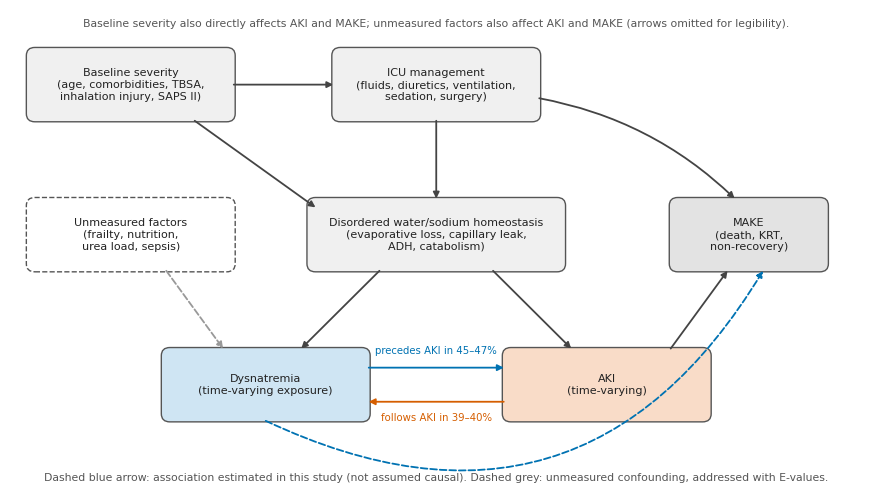

In [15]:
# ---------- Fig R3: DAG
fig,ax=plt.subplots(figsize=(11,6.2)); ax.axis('off'); ax.set_xlim(0,12); ax.set_ylim(0,7)
W,Hh=2.9,1.05
nodes={'sev':(1.7,5.9,'Baseline severity\n(age, comorbidities, TBSA,\ninhalation injury, SAPS II)','#F0F0F0'),
 'tx':(6,5.9,'ICU management\n(fluids, diuretics, ventilation,\nsedation, surgery)','#F0F0F0'),
 'water':(6,3.7,'Disordered water/sodium homeostasis\n(evaporative loss, capillary leak,\nADH, catabolism)','#F0F0F0'),
 'na':(3.6,1.5,'Dysnatremia\n(time-varying exposure)','#CFE5F3'),'aki':(8.4,1.5,'AKI\n(time-varying)','#F9DCC8'),
 'make':(10.4,3.7,'MAKE\n(death, KRT,\nnon-recovery)','#E3E3E3'),'u':(1.7,3.7,'Unmeasured factors\n(frailty, nutrition,\nurea load, sepsis)','#FFFFFF')}
for k,(x,y,t,c) in nodes.items():
    w=W+0.7 if k=='water' else (2.2 if k=='make' else W)
    ax.add_patch(FancyBboxPatch((x-w/2,y-Hh/2),w,Hh,boxstyle='round,pad=0.02,rounding_size=0.12',fc=c,ec='#555555',lw=1,ls='--' if k=='u' else '-')); ax.text(x,y,t,ha='center',va='center',fontsize=8,color=INK)
def A(p,q,rad=0,col='#444444',ls='-'):
    ax.annotate('',xy=q,xytext=p,arrowprops=dict(arrowstyle='-|>',color=col,lw=1.3,ls=ls,shrinkA=0,shrinkB=0,connectionstyle=f'arc3,rad={rad}'))
A((3.15,5.9),(4.55,5.9))            # sev->tx
A((2.6,5.37),(4.3,4.1))             # sev->water
A((6,5.37),(6,4.23))                # tx->water
A((7.45,5.7),(10.2,4.23),-0.15)     # tx->make
A((5.2,3.17),(4.1,2.03))            # water->na
A((6.8,3.17),(7.9,2.03))            # water->aki
A((9.3,2.03),(10.1,3.17))           # aki->make
A((5.05,1.75),(6.95,1.75),-0.0,C_EV) # na->aki
A((6.95,1.25),(5.05,1.25),0.0,C_D)   # aki->na
A((3.6,0.97),(10.6,3.17),0.45,C_EV,'--') # na->make (estimated)
A((2.2,3.17),(3.0,2.03),0,'#999999','--') # u->na
ax.text(6,1.95,'precedes AKI in 45–47%',ha='center',fontsize=7.3,color=C_EV); ax.text(6,0.98,'follows AKI in 39–40%',ha='center',fontsize=7.3,color=C_D)
ax.text(6,6.75,'Baseline severity also directly affects AKI and MAKE; unmeasured factors also affect AKI and MAKE (arrows omitted for legibility).',ha='center',fontsize=7.8,color='#555555')
ax.text(6,0.1,'Dashed blue arrow: association estimated in this study (not assumed causal). Dashed grey: unmeasured confounding, addressed with E-values.',ha='center',fontsize=7.8,color='#555555')
fig.savefig(OUT+'FigR3_DAG.png',dpi=300,bbox_inches='tight'); plt.show()

## 11. Concordance natrémie gaz du sang (ISE directe) / laboratoire (ISE indirecte) et analyses de sensibilité (R1.3)

Lit `outputs/natremia_measurements_long.csv` (notebook 01, §25). Les gaz du sang ne sont datés qu'au jour : l'appariement se fait par **patient-jour** (natrémie labo du jour — moyenne si plusieurs — vs gaz du sang du même jour). Valeurs comparées : `NA_raw_best` après exclusion glycémie/TG (la correction de Katz, identique pour les deux sources le même jour, s'annule dans la différence).

1. Artériel vs veineux (ISE directe, même ligne de gaz) ;
2. Bland–Altman labo − gaz (limites d'agreement corrigées pour mesures répétées : modèle mixte à intercept aléatoire patient) + analyse 1 paire/patient + jours à mesure labo unique ;
3. Concordance de classe (hypo < 135 / normo / hyper > 145) : kappa de Cohen ;
4. Effet de l'albumine / des protéines sur l'écart (effet d'exclusion attendu de l'ISE indirecte) ;
5. Répartition des sources selon le jour de réanimation et la gravité ;
6. Sensibilité : incidence et Cox principal (âge + TBSA, suivi depuis la brûlure) avec labo seul, gaz prioritaire le jour où il existe, labo corrigé du biais estimé.

In [16]:
# ---- 11.1 donnees
import statsmodels.formula.api as smf
R_ise = {}
nat = pd.read_csv(DATA_FOLDER + "natremia_measurements_long.csv", parse_dates=['Date de Prélèvement']).drop_duplicates()
nat = nat[nat.IPP2.isin(df.IPP2)].copy()
nat['day'] = nat['Date de Prélèvement'].dt.normalize()
raw = nat[['NA  :  Sodium','NAGZA  :  Sodium','NAGZV  :  Sodium']].notna().any(axis=1)
R_ise['n_measurements_raw'] = {'all': int(raw.sum()), **{k: int(v) for k, v in nat[raw].source.value_counts().items()},
                               'patients_bga': int(nat[raw & (nat.source=='bga')].IPP2.nunique())}
used = nat.NA_corr_best.notna()
R_ise['n_measurements_used'] = {'all': int(used.sum()), **{k: int(v) for k, v in nat[used].source.value_counts().items()},
                                'patients': int(nat[used].IPP2.nunique()), 'patients_bga': int(nat[used & (nat.source=='bga')].IPP2.nunique())}
print('brutes', R_ise['n_measurements_raw']); print('utilisees', R_ise['n_measurements_used'])

def ba(d):
    """Bland-Altman simple : biais, DS, LoA"""
    m, s = float(d.mean()), float(d.std(ddof=1))
    return {'n': int(len(d)), 'bias': round(m, 2), 'sd': round(s, 2), 'loa': [round(m-1.96*s, 2), round(m+1.96*s, 2)]}
def ba_rm(dd, col='diff'):
    """Bland-Altman mesures repetees (Bland & Altman 2007 ; modele mixte intercept aleatoire patient)"""
    m = smf.mixedlm(f"{col} ~ 1", dd, groups=dd['IPP2']).fit(reml=True)
    b = float(m.params['Intercept']); ci = m.conf_int().loc['Intercept'].tolist()
    sd = float(np.sqrt(m.cov_re.iloc[0, 0] + m.scale))
    return {'pairs': int(len(dd)), 'patients': int(dd.IPP2.nunique()), 'bias': round(b, 2), 'bias_ci': [round(ci[0], 2), round(ci[1], 2)],
            'sd_total': round(sd, 2), 'loa': [round(b-1.96*sd, 2), round(b+1.96*sd, 2)]}

# ---- 11.1 arteriel vs veineux (ISE directe)
av = nat[nat.source=='bga'][['NAGZA  :  Sodium','NAGZV  :  Sodium','IPP2']].dropna()
av = av.assign(diff=av['NAGZA  :  Sodium'] - av['NAGZV  :  Sodium'])
R_ise['art_minus_ven'] = {**ba_rm(av), 'median_abs': float(av['diff'].abs().median()), 'pct_abs_le2': round(100*(av['diff'].abs()<=2).mean(), 1)}
print('Arteriel - veineux :', R_ise['art_minus_ven'])

brutes {'all': 53131, 'lab': 40798, 'bga': 12333, 'patients_bga': 797}
utilisees {'all': 50636, 'lab': 39143, 'bga': 11493, 'patients': 1729, 'patients_bga': 784}


Arteriel - veineux : {'pairs': 6147, 'patients': 502, 'bias': -0.41, 'bias_ci': [-0.52, -0.31], 'sd_total': 3.13, 'loa': [-6.56, 5.73], 'median_abs': 1.0, 'pct_abs_le2': np.float64(86.0)}


In [17]:
# ---- 11.2 paires patient-jour labo / gaz du sang
v = nat[nat.NA_raw_best.notna()]
labd = v[v.source=='lab'].groupby(['IPP2','day']).agg(na_lab=('NA_raw_best','mean'), n_lab=('NA_raw_best','size'),
                                                     alb=('albumin_gL','mean'), prot=('protein_gL','mean')).reset_index()
bgad = v[v.source=='bga'].groupby(['IPP2','day']).agg(na_bga=('NA_raw_best','mean')).reset_index()
pairs = labd.merge(bgad, on=['IPP2','day'])
pairs['diff'] = pairs.na_lab - pairs.na_bga; pairs['mean'] = (pairs.na_lab + pairs.na_bga)/2
pairs = pairs.merge(df[['IPP2','D.entry']], on='IPP2'); pairs['icu_day'] = (pairs.day - pairs['D.entry'].dt.normalize()).dt.days
R_ise['pairs_rm'] = ba_rm(pairs)
R_ise['pairs_single_lab_day'] = ba_rm(pairs[pairs.n_lab==1])
first = pairs.sort_values('day').groupby('IPP2').head(1)
R_ise['pairs_first_per_patient'] = ba(first['diff'])
R_ise['abs_diff'] = {'median': float(pairs['diff'].abs().median()), 'iqr': pairs['diff'].abs().quantile([.25,.75]).tolist(),
                     'pct_le2': round(100*(pairs['diff'].abs()<=2).mean(), 1), 'pct_gt4': round(100*(pairs['diff'].abs()>4).mean(), 1),
                     'pct_lab_higher': round(100*(pairs['diff']>0).mean(), 1), 'pct_lab_lower': round(100*(pairs['diff']<0).mean(), 1)}
# proportionnalite du biais (pente de la difference sur la moyenne)
m = smf.mixedlm("diff ~ I(mean-140)", pairs, groups=pairs.IPP2).fit(reml=True)
R_ise['bias_vs_level'] = [round(float(m.params['I(mean - 140)']), 3)] + [round(float(x), 3) for x in m.conf_int().loc['I(mean - 140)']] + [float(m.pvalues['I(mean - 140)'])]
for k in ['pairs_rm','pairs_single_lab_day','pairs_first_per_patient','abs_diff','bias_vs_level']: print(k, R_ise[k])

# ---- 11.3 concordance de classe
def cls(x): return np.where(x < 135, 'hypo', np.where(x > 145, 'hyper', 'normo'))
def kappa(a, b):
    labs = ['hypo','normo','hyper']; t = pd.crosstab(pd.Categorical(a, labs), pd.Categorical(b, labs), dropna=False).values.astype(float)
    n = t.sum(); po = np.trace(t)/n; pe = (t.sum(0)*t.sum(1)).sum()/n**2
    return (po-pe)/(1-pe), po, t
k, po, t = kappa(cls(pairs.na_lab), cls(pairs.na_bga))
R_ise['class_pairs'] = {'kappa': round(k, 3), 'agreement_pct': round(100*po, 1),
                        'table_rows_lab_cols_bga': t.astype(int).tolist(),
                        'lab_hypo_bga_normo': int(t[0,1]), 'lab_normo_bga_hypo': int(t[1,0]),
                        'lab_hyper_bga_normo': int(t[2,1]), 'lab_normo_bga_hyper': int(t[1,2])}
# bootstrap par patient de l'IC du kappa
rng = np.random.default_rng(42); ids = pairs.IPP2.unique(); g = {i: d for i, d in pairs.groupby('IPP2')}; ks = []
for _ in range(500):
    s = pd.concat([g[i] for i in rng.choice(ids, len(ids))]); ks.append(kappa(cls(s.na_lab), cls(s.na_bga))[0])
R_ise['class_pairs']['kappa_ci'] = [round(float(np.percentile(ks, 2.5)), 3), round(float(np.percentile(ks, 97.5)), 3)]
print('classe', R_ise['class_pairs'])

pairs_rm {'pairs': 11244, 'patients': 775, 'bias': 0.48, 'bias_ci': [0.33, 0.64], 'sd_total': 3.29, 'loa': [-5.96, 6.93]}
pairs_single_lab_day {'pairs': 5202, 'patients': 680, 'bias': 0.22, 'bias_ci': [0.05, 0.38], 'sd_total': 2.85, 'loa': [-5.36, 5.79]}
pairs_first_per_patient {'n': 775, 'bias': 0.36, 'sd': 3.0, 'loa': [-5.53, 6.24]}
abs_diff {'median': 1.6500000000000057, 'iqr': [0.8000000000000114, 2.933333333333337], 'pct_le2': np.float64(58.8), 'pct_gt4': np.float64(12.9), 'pct_lab_higher': np.float64(53.8), 'pct_lab_lower': np.float64(44.9)}
bias_vs_level [-0.172, -0.186, -0.159, 1.1506778751040672e-134]


classe {'kappa': np.float64(0.508), 'agreement_pct': np.float64(80.3), 'table_rows_lab_cols_bga': [[979, 537, 8], [762, 7383, 442], [2, 459, 672]], 'lab_hypo_bga_normo': 537, 'lab_normo_bga_hypo': 762, 'lab_hyper_bga_normo': 459, 'lab_normo_bga_hyper': 442, 'kappa_ci': [0.477, 0.541]}


In [18]:
# ---- 11.4 effet albumine / proteines (exclusion de volume de l'ISE indirecte)
pa = pairs.dropna(subset=['alb']).assign(alb10=lambda d: d.alb/10)
m = smf.mixedlm("diff ~ alb10", pa, groups=pa.IPP2).fit(reml=True)
R_ise['diff_vs_albumin'] = {'pairs': int(len(pa)), 'patients': int(pa.IPP2.nunique()), 'alb_median_iqr': [float(pa.alb.median())] + pa.alb.quantile([.25,.75]).tolist(),
    'slope_per_10gL': [round(float(m.params['alb10']), 2)] + [round(float(x), 2) for x in m.conf_int().loc['alb10']] + [float(m.pvalues['alb10'])],
    'intercept': round(float(m.params['Intercept']), 2)}
pp = pairs.dropna(subset=['prot']).assign(prot10=lambda d: d.prot/10)
m2 = smf.mixedlm("diff ~ prot10", pp, groups=pp.IPP2).fit(reml=True)
R_ise['diff_vs_protein'] = {'pairs': int(len(pp)), 'prot_median_iqr': [float(pp.prot.median())] + pp.prot.quantile([.25,.75]).tolist(),
    'slope_per_10gL': [round(float(m2.params['prot10']), 2)] + [round(float(x), 2) for x in m2.conf_int().loc['prot10']] + [float(m2.pvalues['prot10'])]}
pa['alb_cat'] = pd.cut(pa.alb, [0, 20, 25, 30, 100], right=False, labels=['<20','20–24','25–29','≥30'])
R_ise['bias_by_albumin'] = {str(c): {**ba(d['diff']), 'patients': int(d.IPP2.nunique())} for c, d in pa.groupby('alb_cat', observed=True)}
print('albumine', R_ise['diff_vs_albumin']); print('proteines', R_ise['diff_vs_protein'])
for c, x in R_ise['bias_by_albumin'].items(): print('  albumine', c, x)

# ---- 11.5 repartition des sources (confusion possible)
u = nat[used].merge(df[['IPP2','D.entry','TBSA','MAKE','mechanical_ventilation_D1','hyper','hypo']], on='IPP2')
u['icu_day'] = (u.day - u['D.entry'].dt.normalize()).dt.days
u['day_cat'] = pd.cut(u.icu_day, [-2, 2, 7, 14, 10000], labels=['J-1-J2','J3-J7','J8-J14','>J14'])
R_ise['pct_bga_by_icu_day'] = {str(k): round(100*float(x), 1) for k, x in u.groupby('day_cat', observed=True).source.apply(lambda s: (s=='bga').mean()).items()}
pt = u.groupby('IPP2').agg(frac_bga=('source', lambda s: (s=='bga').mean()), n=('source','size')).join(df.set_index('IPP2')[['TBSA','MAKE','mechanical_ventilation_D1','hyper','hypo']])
def cmp(col):
    a = pt.loc[pt[col]==1, 'frac_bga']; b = pt.loc[pt[col]==0, 'frac_bga']
    return {'yes_median_pct': round(100*a.median(), 1), 'yes_mean_pct': round(100*a.mean(), 1), 'no_median_pct': round(100*b.median(), 1), 'no_mean_pct': round(100*b.mean(), 1)}
pt['tbsa20'] = (pt.TBSA >= 20).astype(int)
R_ise['frac_bga_by_group'] = {c: cmp(c) for c in ['tbsa20','MAKE','mechanical_ventilation_D1','hyper','hypo']}
R_ise['patients_any_bga'] = int((pt.frac_bga > 0).sum())
print('% gaz par jour', R_ise['pct_bga_by_icu_day']); print('fraction gaz par groupe', R_ise['frac_bga_by_group'])

albumine {'pairs': 9210, 'patients': 708, 'alb_median_iqr': [24.0, 21.0, 27.666666666666668], 'slope_per_10gL': [-0.1, -0.23, 0.04, 0.15098470417914345], 'intercept': 0.83}
proteines {'pairs': 11237, 'prot_median_iqr': [53.370000000000005, 48.56, 59.0], 'slope_per_10gL': [-0.82, -0.89, -0.74, 1.3070284181350707e-97]}
  albumine <20 {'n': 1526, 'bias': 0.67, 'sd': 3.28, 'loa': [-5.76, 7.11], 'patients': 261}
  albumine 20–24 {'n': 3546, 'bias': 0.28, 'sd': 3.44, 'loa': [-6.47, 7.03], 'patients': 452}
  albumine 25–29 {'n': 2718, 'bias': 0.54, 'sd': 3.01, 'loa': [-5.35, 6.43], 'patients': 506}
  albumine ≥30 {'n': 1420, 'bias': 0.73, 'sd': 3.21, 'loa': [-5.57, 7.02], 'patients': 490}
% gaz par jour {'J-1-J2': 18.7, 'J3-J7': 21.9, 'J8-J14': 23.5, '>J14': 23.8}
fraction gaz par groupe {'tbsa20': {'yes_median_pct': np.float64(24.7), 'yes_mean_pct': np.float64(22.2), 'no_median_pct': np.float64(0.0), 'no_mean_pct': np.float64(6.4)}, 'MAKE': {'yes_median_pct': np.float64(25.0), 'yes_mean_pct'

In [19]:
# ---- 11.6 sensibilite : definition de l'exposition selon la source
m_alb = smf.mixedlm("diff ~ alb10", pa, groups=pa.IPP2).fit(reml=True)
base = nat[used][['IPP2','Date de Prélèvement','day','source','NA_corr_best','albumin_gL']].copy()
bga_days = set(map(tuple, base.loc[base.source=='bga', ['IPP2','day']].values))
lab_corr = base.copy()
pred = m_alb.params['Intercept'] + m_alb.params['alb10']*lab_corr.albumin_gL/10
lab_corr.loc[lab_corr.source=='lab', 'NA_corr_best'] -= np.where(pred.notna(), pred, R_ise['pairs_rm']['bias'])[lab_corr.source=='lab']
scen = {
    'main_pooled': base,
    'lab_only': base[base.source=='lab'],
    'bga_priority_same_day': base[(base.source=='bga') | ~pd.Series([ (a, b) in bga_days for a, b in zip(base.IPP2, base.day)], index=base.index)],
    'lab_bias_corrected': lab_corr,
}
cols = ['min_natremia_value','max_natremia_value','first_natremia_below_135_date','first_natremia_above_145_date']
orig = df[cols + ['hypo','hyper']].copy()
R_ise['sensitivity'] = {}
for nm, s in scen.items():
    s = s.sort_values('Date de Prélèvement')
    agg = s.groupby('IPP2').NA_corr_best.agg(['min','max'])
    fb = s[s.NA_corr_best < 135].groupby('IPP2')['Date de Prélèvement'].first(); fa = s[s.NA_corr_best > 145].groupby('IPP2')['Date de Prélèvement'].first()
    df['min_natremia_value'] = df.IPP2.map(agg['min']); df['max_natremia_value'] = df.IPP2.map(agg['max'])
    df['first_natremia_below_135_date'] = df.IPP2.map(fb); df['first_natremia_above_145_date'] = df.IPP2.map(fa)
    df['hypo'] = (df.min_natremia_value < 135).astype(int); df['hyper'] = (df.max_natremia_value > 145).astype(int)
    o = {'patients_with_na': int(df.min_natremia_value.notna().sum()), 'hypo': int(df.hypo.sum()), 'hyper': int(df.hyper.sum()),
         'dysnatremia': int((df.hypo | df.hyper).sum()),
         'hypo_pct': round(100*df.hypo.mean(), 1), 'hyper_pct': round(100*df.hyper.mean(), 1), 'dys_pct': round(100*(df.hypo | df.hyper).mean(), 1)}
    R = {}; fit('cox'); o['cox_main'] = {k: R['cox'][k] for k in ['n','events','hyponatremia','hypernatremia']}
    fit('cox_enr', covs=tuple(['Age','TBSA']+ENR), delayed=True); o['cox_enriched'] = {k: R['cox_enr'][k] for k in ['n','events','hyponatremia','hypernatremia']}
    # reclassement patient vs definition principale
    o['reclass_vs_main'] = {'hypo_lost': int(((orig.hypo==1)&(df.hypo==0)).sum()), 'hypo_gained': int(((orig.hypo==0)&(df.hypo==1)).sum()),
                            'hyper_lost': int(((orig.hyper==1)&(df.hyper==0)).sum()), 'hyper_gained': int(((orig.hyper==0)&(df.hyper==1)).sum())}
    R_ise['sensitivity'][nm] = o; print(nm, o)
df[cols + ['hypo','hyper']] = orig   # restauration
json.dump(json.loads(json.dumps(R_ise, default=float)), open(RES + 'R_ise.json', 'w'), indent=1)

cox {'n': 1758, 'events': 222, 'hyponatremia': [1.15, 0.85, 1.55, 0.37683213097537005], 'hypernatremia': [4.03, 2.92, 5.56, 2.2969649647354738e-17]}
cox_enr {'n': 1745, 'events': 212, 'hyponatremia': [1.23, 0.9, 1.68, 0.1956797823208668], 'hypernatremia': [2.34, 1.65, 3.31, 2.0761072256131093e-06]}
main_pooled {'patients_with_na': 1729, 'hypo': 888, 'hyper': 418, 'dysnatremia': 990, 'hypo_pct': np.float64(50.5), 'hyper_pct': np.float64(23.8), 'dys_pct': np.float64(56.3), 'cox_main': {'n': 1758, 'events': 222, 'hyponatremia': [1.15, 0.85, 1.55, 0.37683213097537005], 'hypernatremia': [4.03, 2.92, 5.56, 2.2969649647354738e-17]}, 'cox_enriched': {'n': 1745, 'events': 212, 'hyponatremia': [1.23, 0.9, 1.68, 0.1956797823208668], 'hypernatremia': [2.34, 1.65, 3.31, 2.0761072256131093e-06]}, 'reclass_vs_main': {'hypo_lost': 0, 'hypo_gained': 0, 'hyper_lost': 0, 'hyper_gained': 0}}


cox {'n': 1758, 'events': 222, 'hyponatremia': [1.04, 0.76, 1.42, 0.7953207494117409], 'hypernatremia': [4.32, 3.12, 5.99, 1.3894840551830466e-18]}
cox_enr {'n': 1745, 'events': 212, 'hyponatremia': [1.17, 0.85, 1.6, 0.34786353235186573], 'hypernatremia': [2.52, 1.77, 3.58, 2.8545626164434236e-07]}
lab_only {'patients_with_na': 1729, 'hypo': 843, 'hyper': 393, 'dysnatremia': 963, 'hypo_pct': np.float64(48.0), 'hyper_pct': np.float64(22.4), 'dys_pct': np.float64(54.8), 'cox_main': {'n': 1758, 'events': 222, 'hyponatremia': [1.04, 0.76, 1.42, 0.7953207494117409], 'hypernatremia': [4.32, 3.12, 5.99, 1.3894840551830466e-18]}, 'cox_enriched': {'n': 1745, 'events': 212, 'hyponatremia': [1.17, 0.85, 1.6, 0.34786353235186573], 'hypernatremia': [2.52, 1.77, 3.58, 2.8545626164434236e-07]}, 'reclass_vs_main': {'hypo_lost': 45, 'hypo_gained': 0, 'hyper_lost': 25, 'hyper_gained': 0}}


cox {'n': 1758, 'events': 222, 'hyponatremia': [1.2, 0.88, 1.62, 0.24492585831131347], 'hypernatremia': [3.34, 2.44, 4.59, 7.520722538482078e-14]}
cox_enr {'n': 1745, 'events': 212, 'hyponatremia': [1.19, 0.87, 1.63, 0.2806403143097904], 'hypernatremia': [2.11, 1.51, 2.95, 1.0891987337827418e-05]}
bga_priority_same_day {'patients_with_na': 1729, 'hypo': 866, 'hyper': 366, 'dysnatremia': 970, 'hypo_pct': np.float64(49.3), 'hyper_pct': np.float64(20.8), 'dys_pct': np.float64(55.2), 'cox_main': {'n': 1758, 'events': 222, 'hyponatremia': [1.2, 0.88, 1.62, 0.24492585831131347], 'hypernatremia': [3.34, 2.44, 4.59, 7.520722538482078e-14]}, 'cox_enriched': {'n': 1745, 'events': 212, 'hyponatremia': [1.19, 0.87, 1.63, 0.2806403143097904], 'hypernatremia': [2.11, 1.51, 2.95, 1.0891987337827418e-05]}, 'reclass_vs_main': {'hypo_lost': 22, 'hypo_gained': 0, 'hyper_lost': 52, 'hyper_gained': 0}}


cox {'n': 1758, 'events': 222, 'hyponatremia': [1.05, 0.77, 1.42, 0.759120721956767], 'hypernatremia': [4.09, 2.97, 5.64, 8.098549342622778e-18]}
cox_enr {'n': 1745, 'events': 212, 'hyponatremia': [1.1, 0.81, 1.51, 0.5454806566786168], 'hypernatremia': [2.36, 1.66, 3.34, 1.4514886166331791e-06]}
lab_bias_corrected {'patients_with_na': 1729, 'hypo': 1002, 'hyper': 409, 'dysnatremia': 1086, 'hypo_pct': np.float64(57.0), 'hyper_pct': np.float64(23.3), 'dys_pct': np.float64(61.8), 'cox_main': {'n': 1758, 'events': 222, 'hyponatremia': [1.05, 0.77, 1.42, 0.759120721956767], 'hypernatremia': [4.09, 2.97, 5.64, 8.098549342622778e-18]}, 'cox_enriched': {'n': 1745, 'events': 212, 'hyponatremia': [1.1, 0.81, 1.51, 0.5454806566786168], 'hypernatremia': [2.36, 1.66, 3.34, 1.4514886166331791e-06]}, 'reclass_vs_main': {'hypo_lost': 0, 'hypo_gained': 114, 'hyper_lost': 9, 'hyper_gained': 0}}


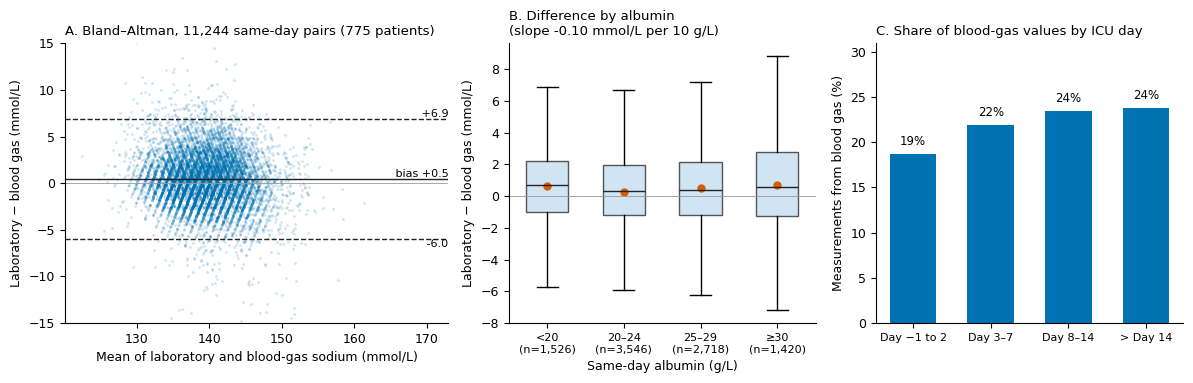

In [20]:
# ---------- Fig R4 : concordance ISE directe / indirecte
fig, axs = plt.subplots(1, 3, figsize=(12, 3.9), gridspec_kw={'width_ratios': [1.25, 1, 1]})
ax = axs[0]; r = R_ise['pairs_rm']
ax.scatter(pairs['mean'], pairs['diff'], s=4, alpha=.18, color=C_EV, lw=0)
for y, ls in [(r['bias'], '-'), (r['loa'][0], '--'), (r['loa'][1], '--')]: ax.axhline(y, color=INK, lw=1, ls=ls)
ax.axhline(0, color='#999999', lw=.6)
ax.text(1.0, r['bias'], f" bias {r['bias']:+.1f}", transform=ax.get_yaxis_transform(), va='bottom', ha='right', fontsize=8)
ax.text(1.0, r['loa'][1], f" {r['loa'][1]:+.1f}", transform=ax.get_yaxis_transform(), va='bottom', ha='right', fontsize=8)
ax.text(1.0, r['loa'][0], f" {r['loa'][0]:+.1f}", transform=ax.get_yaxis_transform(), va='top', ha='right', fontsize=8)
ax.set_xlabel('Mean of laboratory and blood-gas sodium (mmol/L)'); ax.set_ylabel('Laboratory − blood gas (mmol/L)')
ax.set_title(f"A. Bland–Altman, {r['pairs']:,} same-day pairs ({r['patients']:,} patients)", loc='left', fontsize=9.5)
ax.set_ylim(-15, 15)
ax = axs[1]; cats = list(R_ise['bias_by_albumin'].keys())
data = [pa.loc[pa.alb_cat==c, 'diff'] for c in cats]
bp = ax.boxplot(data, showfliers=False, widths=.55, patch_artist=True, medianprops=dict(color=INK))
for b in bp['boxes']: b.set(facecolor='#CFE5F3', edgecolor='#555555')
ax.plot(range(1, len(cats)+1), [R_ise['bias_by_albumin'][c]['bias'] for c in cats], 'o', color=C_D, ms=5, label='mean')
ax.axhline(0, color='#999999', lw=.6); ax.set_xticks(range(1, len(cats)+1)); ax.set_xticklabels([f"{c}\n(n={R_ise['bias_by_albumin'][c]['n']:,})" for c in cats], fontsize=8)
ax.set_xlabel('Same-day albumin (g/L)'); ax.set_ylabel('Laboratory − blood gas (mmol/L)')
sl = R_ise['diff_vs_albumin']['slope_per_10gL']; ax.set_title(f"B. Difference by albumin\n(slope {sl[0]:+.2f} mmol/L per 10 g/L)", loc='left', fontsize=9.5)
ax = axs[2]; d = R_ise['pct_bga_by_icu_day']
ax.bar(range(len(d)), list(d.values()), color=C_EV, width=.6)
for i, x in enumerate(d.values()): ax.text(i, x+1, f'{x:.0f}%', ha='center', fontsize=8.5)
ax.set_xticks(range(len(d))); ax.set_xticklabels(['Day −1 to 2','Day 3–7','Day 8–14','> Day 14'], fontsize=8)
ax.set_ylabel('Measurements from blood gas (%)'); ax.set_ylim(0, max(d.values())*1.3); ax.set_title('C. Share of blood-gas values by ICU day', loc='left', fontsize=9.5)
fig.tight_layout(); fig.savefig(OUT + 'FigR4_ISE_direct_indirect_agreement.png', dpi=300, bbox_inches='tight'); plt.show()